# Contracts: cash flows, conventions and settlement

Family 17. All cash flows and prices are supplied or generated. A contract's
multiplier and settlement convention affect delivery quantities; an FX conversion
factor is supplied explicitly and is not an FX forecast.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(1700)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Coupon schedule and day-count effects

The stub schedule makes the accrual convention visible. Actual/365 and 30/360
give different coupon amounts for the same annual coupon rate.

,Payment date,Day count,Amount
0,2026-07-01,actual365,1.931507
1,2027-01-01,actual365,2.520548
2,2027-07-01,actual365,2.479452
3,2028-01-01,actual365,2.520548
4,2028-01-01,actual365,100.000000
5,2026-07-01,actual360,1.958333
6,2027-01-01,actual360,2.555556
7,2027-07-01,actual360,2.513889
8,2028-01-01,actual360,2.555556
9,2028-01-01,actual360,100.000000


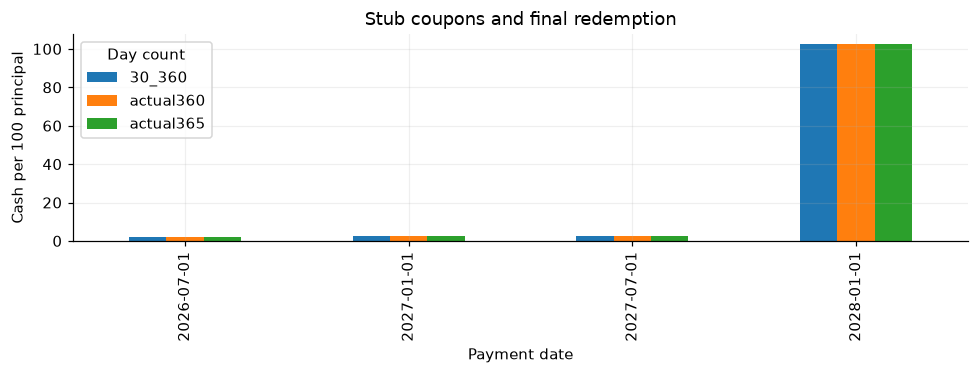

In [2]:
schedule=ct.schedule('2026-02-10','2028-01-01',months=6)
rows=[]
for convention in ['actual365','actual360','30_360']:
    for cf in ct.fixed_cashflows(schedule,.05,convention=convention):
        rows.append((ct.to_date(cf.date).isoformat(),convention,cf.amount))
flows=pd.DataFrame(rows,columns=['Payment date','Day count','Amount'])
display(flows)
flows.groupby(['Payment date','Day count']).Amount.sum().unstack().plot.bar()
plt.ylabel('Cash per 100 principal');plt.title('Stub coupons and final redemption');plt.tight_layout();plt.show()

## Cash versus physical settlement

Physical delivery and its cash leg reconcile to cash exercise value at the
same spot. The table makes the sign of put delivery explicit.

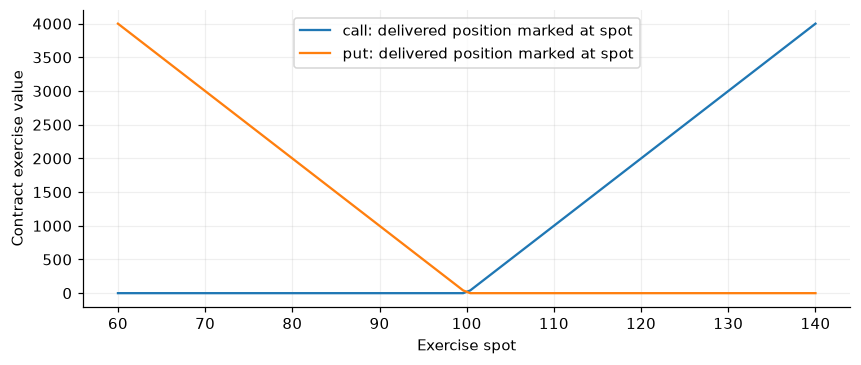

,Kind,Spot,Delivered shares,Cash leg,Value
0,call,80.0,0.0,0.0,0.0
1,call,100.0,0.0,0.0,0.0
2,call,120.0,100.0,-10000.0,2000.0
3,put,80.0,-100.0,10000.0,2000.0
4,put,100.0,0.0,0.0,0.0
5,put,120.0,0.0,0.0,0.0


In [3]:
spots=np.linspace(60,140,100)
rows=[]
for kind in ['call','put']:
    contract=ct.VanillaContract(100.,ct.Exercise('european',(expiry,)),kind,100.,'physical')
    deliveries=[contract.delivery(s) for s in spots]
    value=np.array([units*s+cash for s,(units,cash) in zip(spots,deliveries)])
    plt.plot(spots,value,label=f'{kind}: delivered position marked at spot')
    for spot in [80.,100.,120.]:
        units,cash=contract.delivery(spot)
        rows.append((kind,spot,units,cash,units*spot+cash))
plt.xlabel('Exercise spot');plt.ylabel('Contract exercise value');plt.legend();plt.show()
display(pd.DataFrame(rows,columns=['Kind','Spot','Delivered shares','Cash leg','Value']))

## Corporate actions and conversion conventions

The split and ex-dividend transformations conserve marked wealth under the
specified frictionless assumptions. Compounding frequency changes the accumulation
factor even when the quoted annual rate is unchanged.

,case,shares,price,cash,wealth
0,Before,10.0,100.0,0.0,1000.0
1,4-for-1 split,40.0,25.0,0.0,1000.0
2,Ex-dividend,10.0,98.0,20.0,1000.0


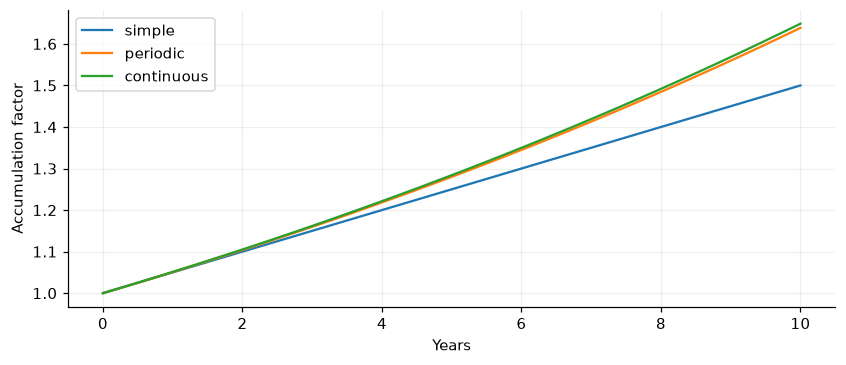

PV of supplied EUR cash flow at 1.10 USD/EUR: 105.68683830675556


In [4]:
q,p=ct.split_holdings(10.,100.,4.)
qd,pd_,cash=ct.dividend_adjustment(10.,100.,2.)
display(pd.DataFrame({'case':['Before','4-for-1 split','Ex-dividend'],
 'shares':[10,q,qd],'price':[100,p,pd_],'cash':[0,0,cash],'wealth':[1000,q*p,qd*pd_+cash]}))
periods=np.linspace(0,10,101)
for convention in ['simple','periodic','continuous']:
    plt.plot(periods,[ct.interest_factor(.05,t,compounding=convention) for t in periods],label=convention)
plt.xlabel('Years');plt.ylabel('Accumulation factor');plt.legend();plt.show()
print('PV of supplied EUR cash flow at 1.10 USD/EUR:',ct.present_value([ct.CashFlow(expiry,100.,'EUR')],discount,fx={'EUR':1.10}))

## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../financial_mathematics.md) and [QA record](../financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.